In [1]:

from pathlib import Path
import json
import joblib
import pandas as pd
import numpy as np

# Locate Member 2's saved artifacts
PROJECT_DIR = Path.cwd() / "member2_submission"
MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR = PROJECT_DIR / "outputs"

# Load the saved model
model = joblib.load(MODEL_DIR / "loan_default_model.pkl")

# Load the feature schema
with open(
    MODEL_DIR / "model_feature_columns.json",
    "r",
    encoding="utf-8"
) as f:
    feature_columns = json.load(f)

# Load the selected threshold
with open(
    MODEL_DIR / "selected_threshold.json",
    "r",
    encoding="utf-8"
) as f:
    threshold_config = json.load(f)

threshold = float(threshold_config["threshold"])

# Load validation data
valid_df = pd.read_pickle(OUTPUT_DIR / "valid_processed.pkl")
X_valid = valid_df[feature_columns]

print("Model:", type(model).__name__)
print("Number of features:", len(feature_columns))
print("Selected threshold:", threshold)
print("Validation shape:", X_valid.shape)



Model: XGBClassifier
Number of features: 226
Selected threshold: 0.15
Validation shape: (61503, 226)


C:\Users\DELL\AppData\Local\Python\pythoncore-3.14-64\Lib\pickle.py:1829: UserWarning: [14:56:48] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\gbm\../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


In [2]:
%pip install shap

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 7.5 MB/s  0:00:00
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)

   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   ------------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


c:\Users\DELL\Desktop\HomeCreditProject\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


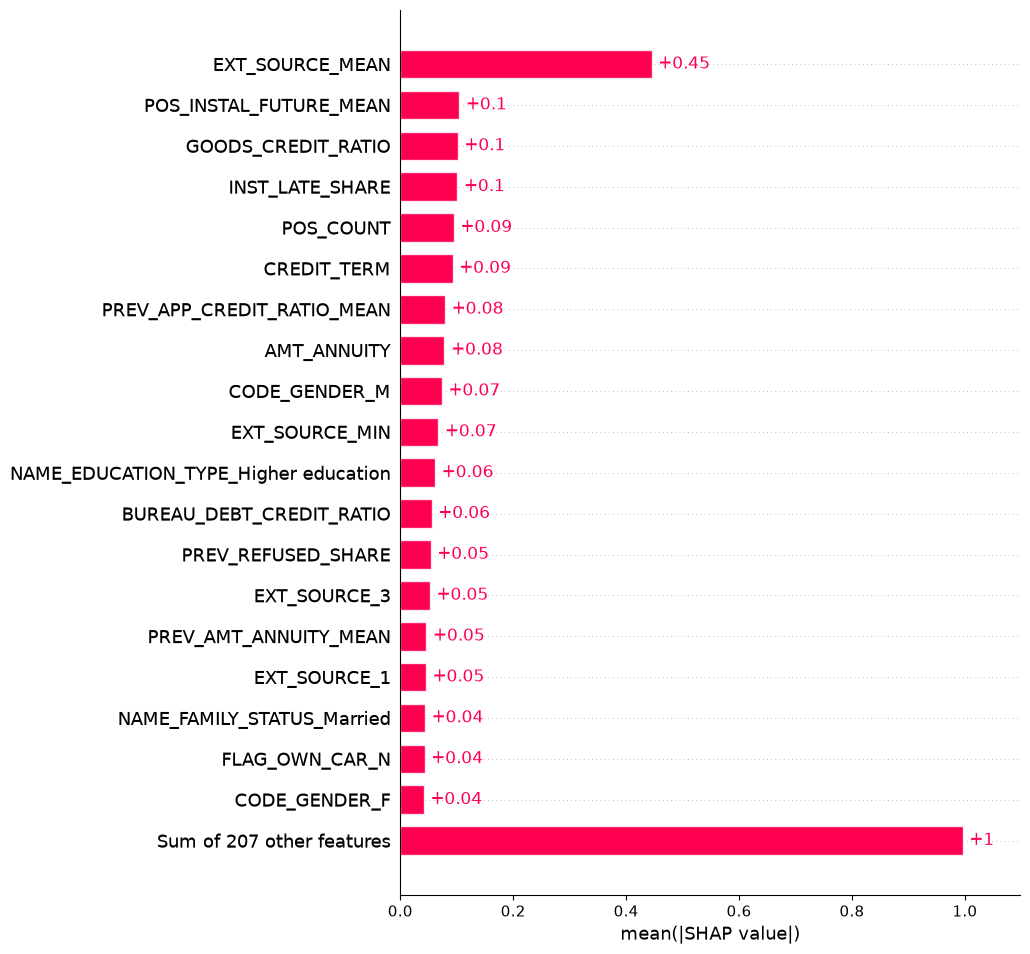

In [3]:

import shap
import matplotlib.pyplot as plt

# Use a manageable validation sample
X_sample = X_valid.sample(
    n=min(300, len(X_valid)),
    random_state=42
)

# Explain the trained model
explainer = shap.TreeExplainer(model)
shap_explanation = explainer(X_sample)

# Global feature importance
shap.plots.bar(shap_explanation, max_display=20)


In [4]:

# Select one applicant from the validation sample
applicant = X_sample.iloc[[0]]

# Calculate the predicted probability
probability = model.predict_proba(applicant)[0, 1]

# Convert probability to a predicted class using your team's threshold
predicted_class = int(probability >= threshold)

print("Probability of repayment difficulties:", round(probability, 4))
print("Selected threshold:", threshold)
print("Predicted class:", predicted_class)

# Display the local explanation
individual_explanation = explainer(applicant)
shap.plots.waterfall(individual_explanation[0, :, 1])


Probability of repayment difficulties: 0.0751
Selected threshold: 0.15
Predicted class: 0


IndexError: too many indices for array

In [5]:

print("SHAP explanation shape:", individual_explanation.shape)
print("SHAP values shape:", np.shape(individual_explanation.values))
print("Base value shape:", np.shape(individual_explanation.base_values))


SHAP explanation shape: (1, 226)
SHAP values shape: (1, 226)
Base value shape: (1,)


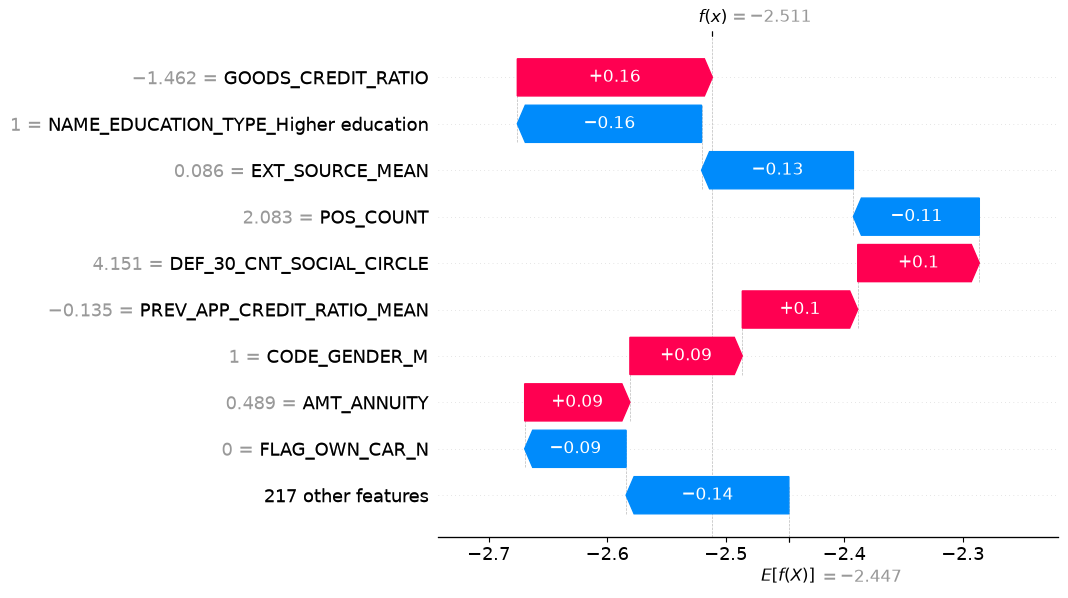

In [6]:

# Display the individual applicant's SHAP explanation
shap.plots.waterfall(individual_explanation[0])


In [7]:

%pip install lime



  Using cached lime-0.2.0.1-py3-none-any.whl
  Using cached scikit_image-0.26.0-cp314-cp314-win_amd64.whl.metadata (15 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached imageio-2.38.1-py3-none-any.whl.metadata (9.7 kB)
  Using cached lazy_loader-0.6-py3-none-any.whl.metadata (6.0 kB)
Using cached scikit_image-0.26.0-cp314-cp314-win_amd64.whl (12.0 MB)
Using cached imageio-2.38.1-py3-none-any.whl (328 kB)
Using cached lazy_loader-0.6-py3-none-any.whl (8.8 kB)
Using cached networkx-3.7-py3-none-any.whl (2.1 MB)

   ---------------------------------------- 0/6 [tifffile]
   ---------------------------------------- 0/6 [tifffile]
   ---------------------------------------- 0/6 [tifffile]
   ---------------------------------------- 0/6 [tifffile]
   ---------------------------------------- 0/6 [tifffile]
   ------ --------------------------------- 1/6 [networkx]
   ------ --------------------------------- 1/6 [networkx]
   ------ -----------------------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:

from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use a manageable sample of the processed training data
train_df = pd.read_pickle(OUTPUT_DIR / "train_processed.pkl")
X_train = train_df[feature_columns]

# Use a sample to reduce memory and computation
lime_background = X_train.sample(
    n=min(2000, len(X_train)),
    random_state=42
)

lime_explainer = LimeTabularExplainer(
    training_data=lime_background.to_numpy(),
    feature_names=feature_columns,
    class_names=["No difficulties", "Repayment difficulties"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

print("LIME explainer created successfully.")


LIME explainer created successfully.


In [9]:

applicant_array = applicant.iloc[0].to_numpy()

lime_explanation = lime_explainer.explain_instance(
    data_row=applicant_array,
    predict_fn=model.predict_proba,
    num_features=10,
    labels=(1,)
)

lime_explanation.show_in_notebook(show_table=True)


ImportError: cannot import name 'display' from 'IPython.core.display' (c:\Users\DELL\Desktop\HomeCreditProject\.venv\Lib\site-packages\IPython\core\display.py)

In [10]:

from IPython.display import display, HTML

display(HTML(lime_explanation.as_html(labels=(1,))))


In [12]:

from pathlib import Path
import sys
import json
import joblib
import pandas as pd

# Locate the main project directory
PROJECT_ROOT = Path.cwd()

# If the notebook is running from another directory, adjust this path
PROJECT_DIR = PROJECT_ROOT / "member2_submission"

# Make member2_submission importable as a Python package
sys.path.insert(0, str(PROJECT_DIR))

MODEL_DIR = PROJECT_DIR / "models"
OUTPUT_DIR = PROJECT_DIR / "outputs"

# Load the model and preprocessing pipeline
model = joblib.load(MODEL_DIR / "loan_default_model.pkl")
pipeline = joblib.load(MODEL_DIR / "preprocessing_pipeline.joblib")

# Load the model's expected feature names
with open(
    MODEL_DIR / "model_feature_columns.json",
    "r",
    encoding="utf-8"
) as f:
    feature_columns = json.load(f)

print("Model loaded:", type(model).__name__)
print("Pipeline loaded:", type(pipeline).__name__)
print("Expected features:", len(feature_columns))


Model loaded: XGBClassifier
Pipeline loaded: Pipeline
Expected features: 226


In [13]:

from src.preprocessing import get_feature_names

# Get the feature names produced by the saved pipeline
pipeline_features = get_feature_names(pipeline)

print("Pipeline feature count:", len(pipeline_features))
print("Model feature count:", len(feature_columns))

# Compare names and order
print(
    "Feature names and order match:",
    pipeline_features == feature_columns
)

# Show any differences
print("Features missing from pipeline:",
      [c for c in feature_columns if c not in pipeline_features][:20])

print("Extra pipeline features:",
      [c for c in pipeline_features if c not in feature_columns][:20])


Pipeline feature count: 226
Model feature count: 226
Feature names and order match: True
Features missing from pipeline: []
Extra pipeline features: []


In [14]:

# Import the prediction function
from src.predict import predict_applicant

# Example applicant — fictional test data, not a real person
test_applicant = {
    "AMT_INCOME_TOTAL": 180000,
    "AMT_CREDIT": 450000,
    "AMT_ANNUITY": 25000,
    "AMT_GOODS_PRICE": 400000,
    "DAYS_BIRTH": -30 * 365,
    "DAYS_EMPLOYED": -5 * 365,
    "CNT_FAM_MEMBERS": 3,
}

result = predict_applicant(test_applicant)

print("Predicted class:", result["predicted_class"])
print("Risk label:", result["risk_label"])
print(f"Difficulty probability: {result['probability']:.2%}")
print(f"Selected threshold: {result['threshold']:.2f}")


Predicted class: 0
Risk label: No repayment difficulties predicted
Difficulty probability: 4.33%
Selected threshold: 0.15
